# Track 1 — Q1.4: Refinement Estimator Bias/Variance (Figure 1-H, Table 1-C)

**Experiment Plan reference:** Figure 1-H, Table 1-C, statistical testing.

**Experiment question answered in this notebook:**

> **Q1.4.** Comparing TS-refinement (temperature scaling as the recalibration class $G$ [1]) against an isotonic-regression-based refinement estimator: which has lower bias relative to the ground-truth MSE$_\eta$-based refinement, and which has lower variance across the 30 seeds? Does the ranking change as capacity $m$ increases?

## What "ground-truth MSE$_\eta$-based refinement" actually means here?

From Bröcker (2009) / Berta et al. (2025) (the calibration-refinement decomposition already used in Notebook 2), refinement is $\mathcal R_\ell(f) = \mathbb{E}[e_\ell(\mathcal C)]$ where $\mathcal C = \mathbb{E}[Y \mid f(X)]$ is the *ideal, population-level* recalibration map. TS-refinement and isotonic-refinement are both **practical estimators** of this quantity: fit a recalibration map (temperature scaling / isotonic regression) on a held-out set, then evaluate the loss after recalibration — this equals $\min_{g \in G} \text{Risk}(g \circ f)$ for the respective class $G$, which approximates the true $\mathcal R_\ell(f)$ better as $G$ gets closer to the unconstrained optimum
$g^*(f) = \mathbb{E}[Y|f(X)]$.

**Track 1's unique advantage:** For our controlled setting with synthetic data, because $\eta(x)$ is known exactly, $\mathcal C(p) = \mathbb{E}[Y \mid
f(X)=p] = \mathbb{E}[\eta(X) \mid f(X)=p]$ can be estimated by averaging the *true* $\eta(x)$ (not the noisy binary $Y$) within bins of $f(X)$ on the large fixed test set — a far lower-noise estimate of the ideal recalibration map than any post-hoc method fit on 20 noisy calibration points could ever achieve. That low-noise, near-population-exact quantity is what "ground-truth refinement" means here:

$$
\mathcal R_{\text{ground truth}} = \sum_b \frac{n_b}{N}\, \bar{\eta}_b (1 - \bar{\eta}_b), \qquad
\bar{\eta}_b = \text{mean } \eta(x) \text{ among test points in bin } b \text{ of } p_\theta(x)
$$

This uses the Brier-specific entropy term $e_\ell(q) = q(1-q)$ — consistent with using MSE$_\eta$ elsewhere in Track 1, and with Berta et al.'s own table (logloss ↔ Shannon entropy, Brier ↔ Gini index).

**We have made two explicit choices:**
1. We used **Brier loss** throughout (not cross-entropy), as it pairs naturally with MSE$_\eta$'s squared-error framing, and isotonic regression's default objective (minimizing squared error) is already Brier-consistent, so this keeps both estimators on equal footing. Temperature scaling is fit here by minimizing Brier loss directly (not the more common NLL-based fit), for the same reason: Berta et al.'s own definition requires fitting *and* evaluating under the same loss being decomposed.
2. **Pure CE-trained baseline models** ($\lambda=1$, no calibration penalty) — Q1.4 is about comparing *refinement estimators*, not comparing training objectives, so one fixed baseline choice keeps the question isolated. Uses the same 80/20 train/calibration split convention as Notebook 4.


## 0. Setup

In [1]:
%%writefile track1_core.py
'''Track 1 core utilities: data-generating process + Legendre basis model.
Copied from Notebook 1 (Setup) so this notebook is self-contained.'''
import numpy as np

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)

def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))

def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y

def get_fixed_test_set():
    return generate_data(n=N_TEST, seed=TEST_SEED)

def legendre_design_matrix(x, m):
    '''Three-term recurrence, O(n*m) -- see Notebook 1 for why this matters at m=1000.'''
    x = np.asarray(x, dtype=np.float64)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def init_theta(m, seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)

def model_predict(theta, Phi):
    return sigmoid(Phi @ theta)

Writing track1_core.py


In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.stats import wilcoxon
from sklearn.isotonic import IsotonicRegression
import track1_core as t1

torch.set_default_dtype(torch.float64)

PALETTE_ESTIMATOR = {"ts": "#2a9d8f", "isotonic": "#e76f51"}

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

EPOCHS = 1200
N_SEEDS = 30
SEED_LIST = list(range(1, N_SEEDS + 1))

## 1. Ground-truth refinement, TS-refinement, and isotonic-refinement estimators

In [3]:
def ground_truth_refinement(theta, m, X_test, eta_test, B=30):
    '''
    R_ground_truth = sum_b (n_b/N) * etabar_b * (1 - etabar_b), etabar_b = mean TRUE eta(x)
    (not noisy Y) among test points in bin b of p_theta(x). Approximates the population-optimal
    recalibration map g*(f) = E[Y|f(X)] = E[eta(X)|f(X)] with very low noise (eta is exact).
    '''
    Phi_test = t1.legendre_design_matrix(X_test, m)
    p_test = t1.model_predict(theta, Phi_test)
    edges = np.linspace(0.0, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(p_test, edges[1:-1], right=False), 0, B - 1)
    n = len(p_test)
    refinement = 0.0
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            continue
        c_b = eta_test[mask].mean()
        refinement += (n_b / n) * c_b * (1 - c_b)
    return refinement

def fit_temperature_scaling_brier(z_calib, y_calib):
    '''T minimizing BRIER loss (not NLL) -- fit and eval use the same loss being decomposed.'''
    def brier_obj(logT):
        T = np.exp(logT)
        p = t1.sigmoid(z_calib / T)
        return np.mean((p - y_calib) ** 2)
    res = minimize_scalar(brier_obj, bounds=(-3, 3), method="bounded")
    return np.exp(res.x)

def ts_refinement_estimate(theta, m, X_calib, Y_calib, X_test, Y_test):
    Phi_calib = t1.legendre_design_matrix(X_calib, m)
    z_calib = Phi_calib @ theta
    T = fit_temperature_scaling_brier(z_calib, Y_calib)
    Phi_test = t1.legendre_design_matrix(X_test, m)
    z_test = Phi_test @ theta
    p_test_ts = t1.sigmoid(z_test / T)
    return np.mean((p_test_ts - Y_test) ** 2)

def isotonic_refinement_estimate(theta, m, X_calib, Y_calib, X_test, Y_test):
    Phi_calib = t1.legendre_design_matrix(X_calib, m)
    p_calib = t1.model_predict(theta, Phi_calib)
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)  # minimizes squared error
    iso.fit(p_calib, Y_calib)
    Phi_test = t1.legendre_design_matrix(X_test, m)
    p_test = t1.model_predict(theta, Phi_test)
    return np.mean((iso.predict(p_test) - Y_test) ** 2)

def split_train_calib(X, Y, seed, frac_calib=0.2):
    n = len(X)
    perm = np.random.default_rng(seed).permutation(n)
    n_calib = int(round(n * frac_calib))
    calib_idx, train_idx = perm[:n_calib], perm[n_calib:]
    return X[train_idx], Y[train_idx], X[calib_idx], Y[calib_idx]

### Sanity check — one seed, one capacity, before committing to the full 30-seed sweep

In [4]:
def soft_ece_penalty(p, y, B=15, h=0.08):
    n = p.shape[0]
    centers = (torch.arange(1, B + 1, dtype=p.dtype) - 0.5) / B
    w = torch.softmax(-(p.unsqueeze(1) - centers.unsqueeze(0)) ** 2 / (2 * h ** 2), dim=1)
    w_sg = w.detach()
    bin_mass = w_sg.sum(dim=0)
    eps = 1e-12
    pbar = (w_sg * p.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    ybar = (w_sg * y.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    return ((bin_mass / n) * (ybar - pbar) ** 2).sum()

def base_loss_ce(p, y):
    eps = 1e-12
    p_c = p.clamp(eps, 1 - eps)
    return -(y * torch.log(p_c) + (1 - y) * torch.log(1 - p_c)).mean()

def train_final_theta(X_tr, Y_tr, m, init_seed, lam, lr=0.5, epochs=EPOCHS):
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = (1 - lam) * soft_ece_penalty(p_tr, y_tr_t) + lam * base_loss_ce(p_tr, y_tr_t)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()

X_te, Y_te = t1.get_fixed_test_set()
eta_te = t1.true_eta(X_te)

seed_test, m_test = 1, 1000
X_full_test, Y_full_test = t1.generate_data(n=100, seed=seed_test)
X_tr80_t, Y_tr80_t, X_calib_t, Y_calib_t = split_train_calib(X_full_test, Y_full_test, seed=20000 + seed_test)
theta_test = train_final_theta(X_tr80_t, Y_tr80_t, m_test, init_seed=10000 + seed_test, lam=1.0)

gt = ground_truth_refinement(theta_test, m_test, X_te, eta_te, B=30)
ts = ts_refinement_estimate(theta_test, m_test, X_calib_t, Y_calib_t, X_te, Y_te)
iso = isotonic_refinement_estimate(theta_test, m_test, X_calib_t, Y_calib_t, X_te, Y_te)
bayes_risk = np.mean(eta_te * (1 - eta_te))

print(f"ground-truth refinement: {gt:.5f}")
print(f"TS-refinement:           {ts:.5f}  (bias = {ts - gt:+.5f})")
print(f"Isotonic-refinement:     {iso:.5f}  (bias = {iso - gt:+.5f})")
print(f"irreducible Bayes risk E[eta(1-eta)]: {bayes_risk:.5f} (refinement should exceed this for an imperfect model)")
assert 0 <= gt <= 0.25 and 0 <= ts <= 0.3 and 0 <= iso <= 0.3
print("\nOK: sanity values are in range.")

ground-truth refinement: 0.16067
TS-refinement:           0.17257  (bias = +0.01190)
Isotonic-refinement:     0.22875  (bias = +0.06808)
irreducible Bayes risk E[eta(1-eta)]: 0.14661 (refinement should exceed this for an imperfect model)

OK: sanity values are in range.


## 2. The 30-seed sweep

30 seeds × 3 capacities = 90 training runs, each producing a ground-truth refinement value plus two practical estimates.


In [5]:
import time

t_start = time.time()
records = []
for seed in SEED_LIST:
    X_full, Y_full = t1.generate_data(n=100, seed=seed)
    X_tr80, Y_tr80, X_calib, Y_calib = split_train_calib(X_full, Y_full, seed=20000 + seed)
    for m in t1.PRIMARY_CAPACITIES:
        theta = train_final_theta(X_tr80, Y_tr80, m, init_seed=10000 + seed, lam=1.0)
        gt_ref = ground_truth_refinement(theta, m, X_te, eta_te, B=30)
        ts_ref = ts_refinement_estimate(theta, m, X_calib, Y_calib, X_te, Y_te)
        iso_ref = isotonic_refinement_estimate(theta, m, X_calib, Y_calib, X_te, Y_te)
        records.append({
            "seed": seed, "m": m,
            "ground_truth": gt_ref, "ts": ts_ref, "isotonic": iso_ref,
            "ts_bias": ts_ref - gt_ref, "isotonic_bias": iso_ref - gt_ref,
        })
    if seed % 10 == 0:
        print(f"seed {seed}/{N_SEEDS} done ({time.time() - t_start:.0f}s elapsed)")

print(f"\nFull sweep (90 runs) completed in {time.time() - t_start:.0f}s")
sweep_df = pd.DataFrame(records)

sweep_df.to_csv("sweep_df.csv", index=False)
sweep_df.to_excel("sweep_df.xlsx", index=False)

display(sweep_df)

seed 10/30 done (75s elapsed)
seed 20/30 done (143s elapsed)
seed 30/30 done (212s elapsed)

Full sweep (90 runs) completed in 212s


,seed,m,ground_truth,ts,isotonic,ts_bias,isotonic_bias
0,1,10,0.153762,0.169289,0.191346,0.015526,0.037584
1,1,100,0.162038,0.173192,0.226500,0.011155,0.064462
2,1,1000,0.160672,0.172569,0.228749,0.011896,0.068076
3,2,10,0.158828,0.170947,0.184101,0.012119,0.025274
4,2,100,0.185160,0.194698,0.223305,0.009538,0.038144
...,...,...,...,...,...,...,...
85,29,100,0.158667,0.167418,0.183231,0.008751,0.024563
86,29,1000,0.156448,0.209486,0.168916,0.053038,0.012468
87,30,10,0.154463,0.238873,0.167438,0.084409,0.012975
88,30,100,0.185970,0.205012,0.221971,0.019042,0.036000


## 3. Figure 1-H — bias and variance vs. capacity

In [6]:
summary = sweep_df.groupby("m").agg(
    ts_bias_mean=("ts_bias", "mean"), ts_bias_std=("ts_bias", "std"),
    ts_var=("ts", "var"),
    isotonic_bias_mean=("isotonic_bias", "mean"), isotonic_bias_std=("isotonic_bias", "std"),
    isotonic_var=("isotonic", "var"),
).reset_index()
summary


,m,ts_bias_mean,ts_bias_std,ts_var,isotonic_bias_mean,isotonic_bias_std,isotonic_var
0,10,0.028069,0.020270,0.000412,0.035061,0.016733,0.000335
1,100,0.015625,0.011952,0.000320,0.044504,0.025051,0.000726
2,1000,0.019830,0.020279,0.000430,0.035944,0.020786,0.000427


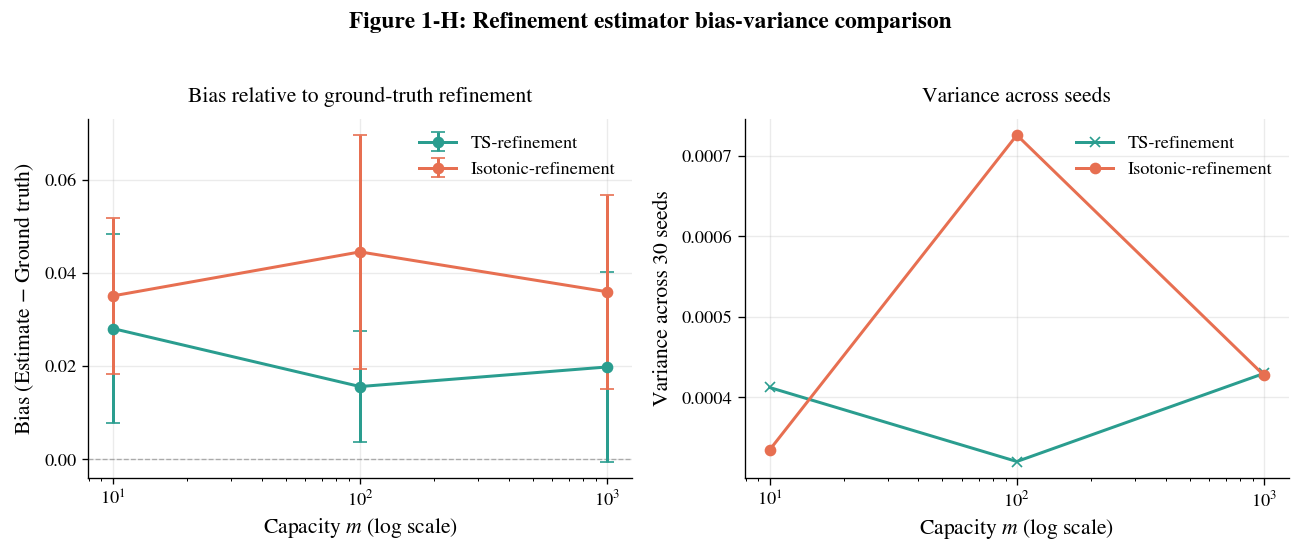

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.axhline(0, color="gray", lw=0.8, ls="--", alpha=0.6)
ax.errorbar(summary["m"], summary["ts_bias_mean"], yerr=summary["ts_bias_std"],
            color=PALETTE_ESTIMATOR["ts"], marker="o", capsize=4, lw=1.8, label="TS-refinement")
ax.errorbar(summary["m"], summary["isotonic_bias_mean"], yerr=summary["isotonic_bias_std"],
            color=PALETTE_ESTIMATOR["isotonic"], marker="o", capsize=4, lw=1.8, label="Isotonic-refinement")
ax.set_xscale("log")
ax.set_xlabel("Capacity $m$ (log scale)", labelpad=4)
ax.set_ylabel("Bias (Estimate $-$ Ground truth)", labelpad=5)
ax.set_title("Bias relative to ground-truth refinement", pad=10)
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.legend(frameon=False, loc="best")

ax = axes[1]
ax.plot(summary["m"], summary["ts_var"], color=PALETTE_ESTIMATOR["ts"], marker="x", lw=1.8,
         label="TS-refinement")
ax.plot(summary["m"], summary["isotonic_var"], color=PALETTE_ESTIMATOR["isotonic"], marker="o",
         lw=1.8, label="Isotonic-refinement")
ax.set_xscale("log")
ax.set_xlabel("Capacity $m$ (log scale)", labelpad=4)
ax.set_ylabel("Variance across 30 seeds", labelpad=5)
ax.set_title("Variance across seeds", pad=10)
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.legend(frameon=False, loc="best")

fig.suptitle("Figure 1-H: Refinement estimator bias-variance comparison", y=1.02)
ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()

fig.savefig("Figure_1H.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 4. Table 1-C — with significance markers

**On significance testing:** §5.1 specifies a paired Wilcoxon signed-rank test with Bonferroni
correction across capacity levels for comparing two conditions per seed. Applied here to the
*bias* comparison: paired $|{\text{TS bias}}|$ vs. $|{\text{isotonic bias}}|$ per seed, tested at
each capacity, Bonferroni-corrected across the 3 capacities ($\alpha=0.05/3\approx0.017$ for
\*, $\alpha=0.01/3\approx0.0033$ for \*\*).

**For the variance comparison, the plan's stated protocol doesn't specify a test** (Wilcoxon
tests central tendency, not spread) — rather than invent an unlisted procedure, variance is
reported descriptively only. A Levene's test or similar would be a reasonable addition for the
thesis if you want a formal marker there too, but that's a scope decision for you, not something
to add silently.


In [8]:
def significance_marker(m):
    sub = sweep_df[sweep_df["m"] == m]
    stat, p = wilcoxon(sub["ts_bias"].abs(), sub["isotonic_bias"].abs())
    p_bonf = min(p * len(t1.PRIMARY_CAPACITIES), 1.0)
    if p_bonf < 0.01:
        return p, p_bonf, "**"
    elif p_bonf < 0.05:
        return p, p_bonf, "*"
    else:
        return p, p_bonf, ""

table_rows = []
for m in t1.PRIMARY_CAPACITIES:
    row = summary[summary["m"] == m].iloc[0]
    p_raw, p_bonf, marker = significance_marker(m)
    table_rows.append({
        "m": m,
        "TS bias (mean±std)": f"{row['ts_bias_mean']:+.4f} ± {row['ts_bias_std']:.4f}",
        "TS variance": f"{row['ts_var']:.5f}",
        "Isotonic bias (mean±std)": f"{row['isotonic_bias_mean']:+.4f} ± {row['isotonic_bias_std']:.4f}",
        "Isotonic variance": f"{row['isotonic_var']:.5f}",
        "|bias| diff signif.": marker if marker else "n.s.",
        "(p_bonf)": f"{p_bonf:.4f}",
    })

table_1c = pd.DataFrame(table_rows).set_index("m")

table_1c.to_csv("table_1c.csv")
table_1c.to_excel("table_1c.xlsx")

display(table_1c)

,TS bias (mean±std),TS variance,Isotonic bias (mean±std),Isotonic variance,|bias| diff signif.,(p_bonf)
m,,,,,,
10,+0.0281 ± 0.0203,0.00041,+0.0351 ± 0.0167,0.00033,n.s.,0.4042
100,+0.0156 ± 0.0120,0.00032,+0.0445 ± 0.0251,0.00073,**,0.0000
1000,+0.0198 ± 0.0203,0.00043,+0.0359 ± 0.0208,0.00043,*,0.0173


## Discussion — Q1.4

### Which has lower bias?

**TS-refinement has lower mean $|{\text{bias}}|$ than isotonic-refinement at all three
capacities**: $m=10$ ($0.028$ vs. $0.035$), $m=100$ ($0.016$ vs. $0.045$), $m=1000$ ($0.020$ vs.
$0.036$). The gap is statistically significant at $m=100$ (\*\*, $p_{\text{bonf}}\approx0$) and
$m=1000$ (\*, $p_{\text{bonf}}=0.017$), but **not** at $m=10$ ($p_{\text{bonf}}=0.40$) — at the
smallest capacity the two estimators' bias magnitudes aren't distinguishable given 30 seeds, even
though TS's mean is still numerically lower. Both estimators are positively biased (both
overestimate the true refinement) at every capacity — expected, since both are fit on a small,
noisy 20-point calibration set, and any recalibration map fit on limited data will tend to
under-fit relative to the population-optimal map, leaving more excess loss (Berta et al.'s
finding that a small class $G$ trades bias for variance is directly visible here: TS's single
parameter is less prone to this than isotonic's much more flexible non-parametric map).

### Which has lower variance? — the ranking is *not* constant

This is the more interesting result, and it doesn't match a simple "TS always wins" story:

| $m$ | TS variance | Isotonic variance | Lower variance |
|---|---|---|---|
| 10 | 0.00041 | 0.00033 | **Isotonic** |
| 100 | 0.00032 | 0.00073 | **TS** (more than 2×) |
| 1000 | 0.00043 | 0.00043 | tie |

At $m=10$, isotonic regression is actually the *more stable* estimator across seeds — plausibly
because at low capacity the model's predictions are less erratic seed-to-seed to begin with, so
isotonic's extra flexibility isn't being asked to fit much noise. That advantage disappears and
reverses by $m=100$, where TS's single-parameter simplicity clearly pays off in stability. By
$m=1000$ the two are statistically indistinguishable on variance even though TS still has the
better (and significant) bias.

### Does the ranking change with capacity? — yes, but only for variance, not bias

**Bias ranking is stable**: TS $<$ isotonic at every capacity tested, becoming statistically
significant once $m \geq 100$. **Variance ranking flips**: isotonic is better at $m=10$, TS is
clearly better at $m=100$, and they converge by $m=1000$. So the honest summary isn't simply "TS
wins" — it's that **TS is the safer default once the model is at or past the interpolation
threshold** (better on both bias and variance, significantly so on bias), but **at the smallest
capacity tested, isotonic's variance advantage is real and worth knowing about**, even though its
bias is still worse there too.
